# 03 · Heart Disease — An End-to-End scikit-learn Pipeline

**Question.** Predict heart disease from clinical measurements, with preprocessing and model selection packaged
into one reproducible object.

**Data.** 589 patients for training and 197 for a separate hold-out test; 11 features, 6 numeric and 5 categorical.
Missing values in `Age`, `RestingBP` and `Cholesterol` (127 of 589 rows).

**Approach.** `ColumnTransformer` (imputation, scaling, one-hot encoding) inside a `Pipeline` → `GridSearchCV` over
**80 combinations** of three model families (logistic regression, random forest, gradient boosting) *and* the
imputation strategy → one final evaluation on unseen data.

**Result.** Random forest, ROC-AUC **0.936** in 5-fold cross-validation and **0.917** on the hold-out test
(required threshold: 0.87).

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score, roc_curve

RANDOM_STATE = 12345

## 1. Training data

In [2]:
train = pd.read_csv('../data/heart_adapt_train.csv')
print('training set shape:', train.shape)
train.head()

training set shape: (589, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,74.0,M,NAP,138.0,NaN,0,Normal,116,N,0.2,Up,0
1,58.0,M,NAP,132.0,224.0,0,LVH,173,N,3.2,Up,1
2,44.0,M,ATA,150.0,288.0,0,Normal,150,Y,3.0,Flat,1
3,50.0,M,ASY,144.0,349.0,0,LVH,120,Y,1.0,Up,1
4,NaN,M,ASY,145.0,248.0,0,Normal,96,Y,2.0,Flat,1


In [3]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 589 entries, 0 to 588
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             533 non-null    float64
 1   Sex             589 non-null    str    
 2   ChestPainType   589 non-null    str    
 3   RestingBP       588 non-null    float64
 4   Cholesterol     462 non-null    float64
 5   FastingBS       589 non-null    int64  
 6   RestingECG      589 non-null    str    
 7   MaxHR           589 non-null    int64  
 8   ExerciseAngina  589 non-null    str    
 9   Oldpeak         589 non-null    float64
 10  ST_Slope        589 non-null    str    
 11  HeartDisease    589 non-null    int64  
dtypes: float64(4), int64(3), str(5)
memory usage: 55.3 KB


In [4]:
# missing values
na = train.isna().sum()
na[na > 0]

Age             56
RestingBP        1
Cholesterol    127
dtype: int64

In [5]:
print(train['HeartDisease'].value_counts())
print()
print(train['HeartDisease'].value_counts(normalize=True).round(3))

HeartDisease
1    381
0    208
Name: count, dtype: int64

HeartDisease
1    0.647
0    0.353
Name: proportion, dtype: float64


In [6]:
features_train = train.drop(columns='HeartDisease')
target_train = train['HeartDisease']

numeric_features = features_train.select_dtypes(include='number').columns.tolist()
categorical_features = [c for c in features_train.columns if c not in numeric_features]

print('numeric:    ', numeric_features)
print('categorical:', categorical_features)

numeric:     ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']
categorical: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']


## 2. The pipeline

Every preprocessing step lives inside the pipeline, so during cross-validation imputation values and scaling
parameters are learned from the training folds only — no information leaks from the validation folds.

In [7]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ohe', OneHotEncoder(handle_unknown='ignore', drop='first'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(solver='liblinear', random_state=RANDOM_STATE))
])

pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the

In [8]:
# sanity check that the whole pipeline runs: baseline quality before any tuning
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
base_scores = cross_val_score(pipeline, features_train, target_train,
                              cv=cv, scoring='roc_auc')

print('ROC-AUC per fold:', base_scores.round(4))
print('baseline (logistic regression): {:.4f}'.format(base_scores.mean()))

ROC-AUC per fold: [0.958  0.9082 0.9032 0.9566 0.9275]
baseline (logistic regression): 0.9307


## 3. Model and preprocessing search

The grid swaps the model itself and tunes the numeric imputation strategy at the same time:
8 logistic regression + 48 random forest + 24 gradient boosting configurations.

In [9]:
param_grid = [
    # linear model
    {
        'preprocessor__num__imputer__strategy': ['median', 'mean'],
        'model': [LogisticRegression(solver='liblinear', max_iter=1000,
                                     random_state=RANDOM_STATE)],
        'model__C': [0.01, 0.1, 1, 10]
    },
    # random forest
    {
        'preprocessor__num__imputer__strategy': ['median', 'mean'],
        'model': [RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)],
        'model__n_estimators': [200, 500],
        'model__max_depth': [3, 5, 8, None],
        'model__min_samples_leaf': [1, 3, 5]
    },
    # gradient boosting
    {
        'preprocessor__num__imputer__strategy': ['median', 'mean'],
        'model': [HistGradientBoostingClassifier(random_state=RANDOM_STATE)],
        'model__max_depth': [2, 3, None],
        'model__learning_rate': [0.05, 0.1],
        'model__max_iter': [200, 400]
    }
]

grid_search = GridSearchCV(pipeline, param_grid,
                           scoring='roc_auc',
                           cv=cv,
                           n_jobs=-1,
                           refit=True)

grid_search.fit(features_train, target_train)

print('combinations tried:', len(grid_search.cv_results_['params']))
print('best ROC-AUC, cross-validation: {:.4f}'.format(grid_search.best_score_))
print()
for name, value in grid_search.best_params_.items():
    print('{}: {}'.format(name, value))

combinations tried: 80
best ROC-AUC, cross-validation: 0.9360

model: RandomForestClassifier(n_jobs=-1, random_state=12345)
model__max_depth: 8
model__min_samples_leaf: 1
model__n_estimators: 500
preprocessor__num__imputer__strategy: mean


In [10]:
best_pipeline = grid_search.best_estimator_
best_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['Age','Sex','ChestPainType',...,'ExerciseAngina','Oldpeak','ST_Slope']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all 

## 4. Final evaluation on the hold-out test set

The test file was not used for anything above. It also contains missing values, which the fitted pipeline fills
using what it learned from the training data.

In [11]:
test = pd.read_csv('../data/heart_adapt_test.csv')

features_test = test.drop(columns='HeartDisease')
target_test = test['HeartDisease']

print('test set shape:', features_test.shape)
print('missing values in test features:', features_test.isna().sum().sum())
features_test.head()

test set shape: (197, 11)
missing values in test features: 57


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope
0,44.0,M,NAP,130.0,233.0,0,Normal,179,Y,0.4,Up
1,63.0,M,ASY,130.0,308.0,0,Normal,138,Y,2.0,Flat
2,35.0,F,TA,120.0,160.0,0,ST,185,N,0.0,Up
3,69.0,M,NAP,140.0,NaN,1,ST,118,N,2.5,Down
4,NaN,M,TA,142.0,200.0,1,ST,100,N,1.5,Down


In [12]:
probabilities_test = best_pipeline.predict_proba(features_test)[:, 1]
roc_auc_test = roc_auc_score(target_test, probabilities_test)

print('ROC-AUC on the test set: {:.4f}'.format(roc_auc_test))
print('required threshold 0.87 —', 'passed' if roc_auc_test >= 0.87 else 'NOT passed')

ROC-AUC on the test set: 0.9168
required threshold 0.87 — passed


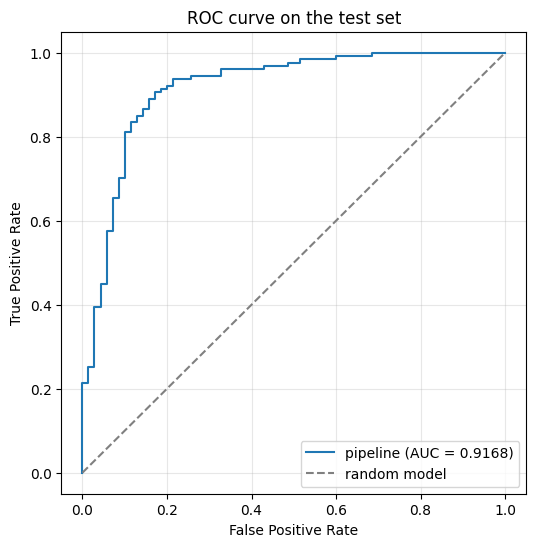

In [13]:
fpr, tpr, _ = roc_curve(target_test, probabilities_test)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label='pipeline (AUC = {:.4f})'.format(roc_auc_test))
plt.plot([0, 1], [0, 1], '--', color='gray', label='random model')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC curve on the test set')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

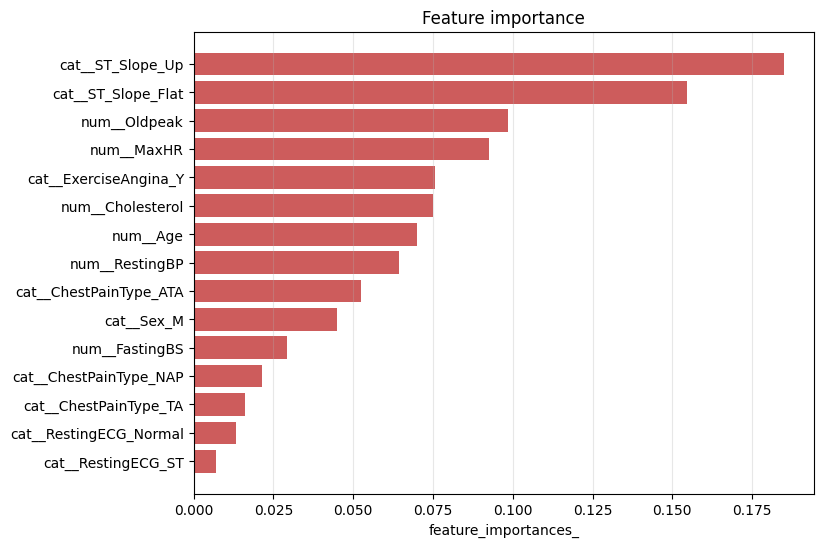

cat__ST_Slope_Up          0.1851
cat__ST_Slope_Flat        0.1546
num__Oldpeak              0.0986
num__MaxHR                0.0925
cat__ExerciseAngina_Y     0.0755
num__Cholesterol          0.0749
num__Age                  0.0701
num__RestingBP            0.0645
cat__ChestPainType_ATA    0.0523
cat__Sex_M                0.0450
num__FastingBS            0.0294
cat__ChestPainType_NAP    0.0213
cat__ChestPainType_TA     0.0160
cat__RestingECG_Normal    0.0132
cat__RestingECG_ST        0.0070
dtype: float64

In [14]:
feature_names = best_pipeline.named_steps['preprocessor'].get_feature_names_out()
importances = pd.Series(
    best_pipeline.named_steps['model'].feature_importances_,
    index=feature_names
).sort_values(ascending=False)

plt.figure(figsize=(8, 6))
plt.barh(importances.index[::-1], importances.values[::-1], color='indianred')
plt.xlabel('feature_importances_')
plt.title('Feature importance')
plt.grid(axis='x', alpha=0.3)
plt.show()

importances.round(4)

## 5. Conclusions

The best model is a **random forest** (`max_depth=8`, `min_samples_leaf=1`, `n_estimators=500`) with mean imputation
for numeric gaps: ROC-AUC **0.9360** in cross-validation and **0.9168** on the untouched test set. The small drop from
cross-validation to test is expected and shows the model was not overfitted to the training folds.

The most informative features are the results of the exercise stress test: `ST_Slope`, `Oldpeak`, `MaxHR` and
`ExerciseAngina`.

Packaging preprocessing and the model into a single pipeline is what makes the result trustworthy: the same object
that was cross-validated is the one applied to new data, with no manual steps in between.